# Aufgabe 2 – Model Baseline und Data Preparation
**Data Science WS 2026/27 | HdM**

Zuerst wird eine Baseline mit minimaler Vorverarbeitung erstellt. Danach werden die Datenqualitätsprobleme aus Aufgabe 1 Schritt für Schritt behoben und jeder Schritt mit einer linearen Regression auf der Validierung bewertet (MAE, R²). In Validierung und Test werden keine Zeilen entfernt und keine Labels verändert, alle Parameter kommen nur aus den Trainingsdaten.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import PowerTransformer, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 1. Daten laden und Split
Gleicher Split wie in Aufgabe 1 (80/20, `random_state=42`). Trainingszeilen ohne Label werden vorher entfernt.

In [2]:
DATA_DIR = "../Data/"
LABEL = "pm25_target"
LOG_FILE = DATA_DIR + "task2_log.txt"

df = pd.read_csv(DATA_DIR + "pm25_train.csv")
test = pd.read_csv(DATA_DIR + "pm25_test.csv")

labeled = df.dropna(subset=[LABEL]).copy()
train, valid = train_test_split(labeled, test_size=0.20, random_state=42)
print("Training:", len(train), "| Validierung:", len(valid), "| Test:", len(test),
      "| Testzeilen ohne Label:", test[LABEL].isnull().sum())

Training: 2727 | Validierung: 682 | Test: 1464 | Testzeilen ohne Label: 45


### Handlungsempfehlungen aus Aufgabe 1

| Befund aus Aufgabe 1 | Schritt in Aufgabe 2 |
|---|---|
| negative Werte bei `no` (Minimum −2,7) | 4.1 negative Werte auf 0 setzen |
| viele Ausreißer, `pm25_lowcost` bis 595 bei Median 2,7 | 4.2 Ausreißer kappen |
| fehlende Werte bei `co2`, `ufp`, `o3`, `pm25_lowcost` und Wetterdaten | 4.3 fehlende Werte je Feature füllen |
| `pm25_lowcost` korreliert kaum mit dem Label (r = 0,08) | 4.2 und 4.4 neues Feature mit der Luftfeuchte |
| schiefe Verteilungen, sehr unterschiedliche Wertebereiche | 4.5 Transformation und Skalierung |
| korrelierte Features, `no2` hat in 1b verschlechtert | 4.6 Feature Selection |

## 2. Hilfsfunktionen
`evaluate` trainiert die lineare Regression, berechnet MAE und R² samt Veränderung zur Baseline und schreibt alles ins Log-File. `check_integrity` prüft, dass Validierung und Test vollständig und die Labels unverändert sind.

In [3]:
def feature_columns(data):
    return [col for col in data.columns if col not in [LABEL, "timestamp", "year_month"]]


VAL_LABEL_ORIGINAL = valid[LABEL].copy()
TEST_LABEL_ORIGINAL = test[LABEL].copy()


def check_integrity(val_df, test_df):
    # Validierung und Test: keine Zeile entfernt, Labels unverändert
    for data, original in [(val_df, VAL_LABEL_ORIGINAL), (test_df, TEST_LABEL_ORIGINAL)]:
        assert len(data) == len(original)
        assert (data.index == original.index).sum() == len(original)
        assert (data[LABEL] - original).abs().sum() == 0
        assert data[LABEL].isnull().sum() == original.isnull().sum()


with open(LOG_FILE, "w", encoding="utf-8") as log:
    log.write("Modell | Art | Beschreibung | Features | MAE Train | MAE Val | R2 Train | R2 Val | dMAE vs. Baseline\n")

results = []
BASELINE = {}


def evaluate(name, art, beschreibung, train_df, val_df):
    features = feature_columns(train_df)
    # verbleibende NaN mit dem Trainings-Median füllen (LinearRegression kann keine NaN)
    median = train_df[features].median()
    X_train = train_df[features].fillna(median)
    X_val = val_df[features].fillna(median)

    reg = linear_model.LinearRegression()
    reg.fit(X_train, train_df[LABEL])

    row = {"Modell": name, "Art": art, "Features": len(features),
           "MAE_Train": mean_absolute_error(train_df[LABEL], reg.predict(X_train)),
           "MAE_Val": mean_absolute_error(val_df[LABEL], reg.predict(X_val)),
           "R2_Train": reg.score(X_train, train_df[LABEL]),
           "R2_Val": reg.score(X_val, val_df[LABEL])}
    base_mae = BASELINE["MAE_Val"] if BASELINE else row["MAE_Val"]
    base_r2 = BASELINE["R2_Val"] if BASELINE else row["R2_Val"]
    row["dMAE_abs"] = row["MAE_Val"] - base_mae
    row["dMAE_%"] = row["dMAE_abs"] / base_mae * 100
    row["dR2_abs"] = row["R2_Val"] - base_r2
    row["Übernommen"] = "-"
    results.append(row)

    with open(LOG_FILE, "a", encoding="utf-8") as log:
        log.write(f"{name} | {art} | {beschreibung} | {len(features)} | {row['MAE_Train']:.4f} | "
                  f"{row['MAE_Val']:.4f} | {row['R2_Train']:.4f} | {row['R2_Val']:.4f} | {row['dMAE_abs']:+.4f}\n")
    return row


def improves(row):
    # Regel: MAE auf der Validierung sinkt und R² wird nicht schlechter
    return row["MAE_Val"] < current["MAE_Val"] and row["R2_Val"] >= current["R2_Val"]


def adopt(row, decision, reason):
    row["Übernommen"] = decision
    with open(LOG_FILE, "a", encoding="utf-8") as log:
        log.write(f"ENTSCHEIDUNG {row['Modell']}: {decision} ({reason})\n")


def show(rows):
    cols = ["Modell", "Art", "MAE_Train", "MAE_Val", "R2_Train", "R2_Val", "dMAE_abs", "dMAE_%", "dR2_abs", "Übernommen"]
    return pd.DataFrame(rows)[cols].round(4)

## 3. Baseline
Alle 14 numerischen Features, fehlende Werte mit dem Trainings-Median gefüllt (die lineare Regression kann keine NaN verarbeiten). Zur Einordnung: eine naive Vorhersage, die immer den Mittelwert vorhersagt.

MAE naive Vorhersage (Mittelwert): 1.7523
MAE Baseline: 1.3417 | R²: 0.359
Koeffizient pm25_lowcost: 0.0045 | Koeffizient black_carbon: 0.598


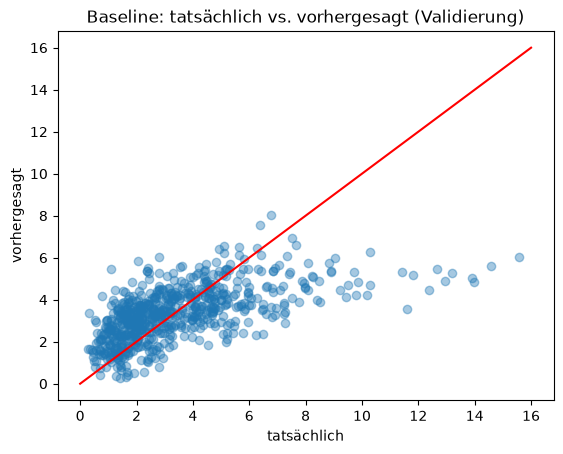

In [4]:
baseline = evaluate("Baseline", "Baseline", "Originaldaten, 14 numerische Features, NaN mit Trainings-Median", train, valid)
BASELINE = baseline

features = feature_columns(train)
median = train[features].median()
reg_baseline = linear_model.LinearRegression()
reg_baseline.fit(train[features].fillna(median), train[LABEL])
pred_val_baseline = reg_baseline.predict(valid[features].fillna(median))

print("MAE naive Vorhersage (Mittelwert):", round(mean_absolute_error(valid[LABEL], [train[LABEL].mean()] * len(valid)), 4))
print("MAE Baseline:", round(baseline["MAE_Val"], 4), "| R²:", round(baseline["R2_Val"], 4))
print("Koeffizient pm25_lowcost:", round(reg_baseline.coef_[0], 4), "| Koeffizient black_carbon:", round(reg_baseline.coef_[5], 4))

plt.scatter(valid[LABEL], pred_val_baseline, alpha=0.4)
plt.plot([0, 16], [0, 16], color="red")
plt.title("Baseline: tatsächlich vs. vorhergesagt (Validierung)")
plt.xlabel("tatsächlich")
plt.ylabel("vorhergesagt")
plt.show()

- MAE 1,342 und R² 0,359, genau wie das Modell mit allen Features aus 1b. Die naive Vorhersage schafft 1,752, die Baseline ist also nur 23 % besser.
- Der Koeffizient von `pm25_lowcost` ist nur 0,0045, obwohl beide Geräte dasselbe messen. Die Ausreißer bis 595 µg/m³ drücken die Steigung fast auf 0, hohe Werte werden stark unterschätzt.

## 4. Data Preparation
Jeder Schritt wird kumulativ (zusammen mit den bisher übernommenen Schritten) und isoliert (allein auf den Originaldaten) bewertet. Übernommen wird ein Schritt, wenn der Validierungs-MAE sinkt und R² nicht schlechter wird.

In [5]:
train_cur, valid_cur, test_cur = train.copy(), valid.copy(), test.copy()
current = baseline
path = [baseline]      # übernommene Schritte

### 4.1 Negative Werte
Konzentrationen können nicht negativ sein, negative Werte werden auf 0 gesetzt.

In [6]:
CONC_COLS = ["pm25_lowcost", "no", "no2", "o3", "co2", "black_carbon", "ufp"]


def clip_negative(train_df, val_df, test_df):
    result = []
    for data in [train_df, val_df, test_df]:
        data = data.copy()
        for col in CONC_COLS:
            data[col] = data[col].clip(lower=0)
        result.append(data)
    return result[0], result[1], result[2]


tr, va, te = clip_negative(train_cur, valid_cur, test_cur)
check_integrity(va, te)
print(pd.DataFrame({"Train vorher": (train_cur[CONC_COLS] < 0).sum(), "Train nachher": (tr[CONC_COLS] < 0).sum(),
                    "Test vorher": (test_cur[CONC_COLS] < 0).sum(), "Test nachher": (te[CONC_COLS] < 0).sum()}))

r_negativ = evaluate("Negativwerte auf 0", "kumulativ", "negative Konzentrationen auf 0 gesetzt", tr, va)
r_negativ_iso = evaluate("Negativwerte auf 0", "isoliert", "negative Konzentrationen auf 0 gesetzt", tr, va)
if improves(r_negativ):
    train_cur, valid_cur, test_cur, current = tr, va, te, r_negativ
    path.append(r_negativ)
    adopt(r_negativ, "ja", "MAE sinkt, Werte sind physikalisch unmöglich")
show([baseline, r_negativ])

              Train vorher  Train nachher  Test vorher  Test nachher
pm25_lowcost             0              0            0             0
no                     376              0           99             0
no2                      0              0            0             0
o3                       0              0          142             0
co2                      0              0            0             0
black_carbon             0              0            0             0
ufp                      0              0            0             0


,Modell,Art,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_%,dR2_abs,Übernommen
0,Baseline,Baseline,1.3261,1.3417,0.3183,0.3590,0.0000,0.0000,0.0000,-
1,Negativwerte auf 0,kumulativ,1.3257,1.3412,0.3186,0.3594,-0.0005,-0.0382,0.0004,ja


Betroffen sind `no` und im Test zusätzlich `o3`. Der Effekt ist minimal (MAE −0,0005), da die Werte nahe 0 liegen.

### 4.2 Ausreißer
Ausreißer der Schadstoff-Features werden mit der IQR-Regel erkannt und durch das 5. bzw. 95. Perzentil ersetzt (Grenzen aus den Trainingsdaten). Extreme Wetterwerte sind echte Messungen und bleiben. Kappen statt Löschen, weil im Test keine Zeilen fehlen dürfen und die Information „hoher Wert“ erhalten bleibt.

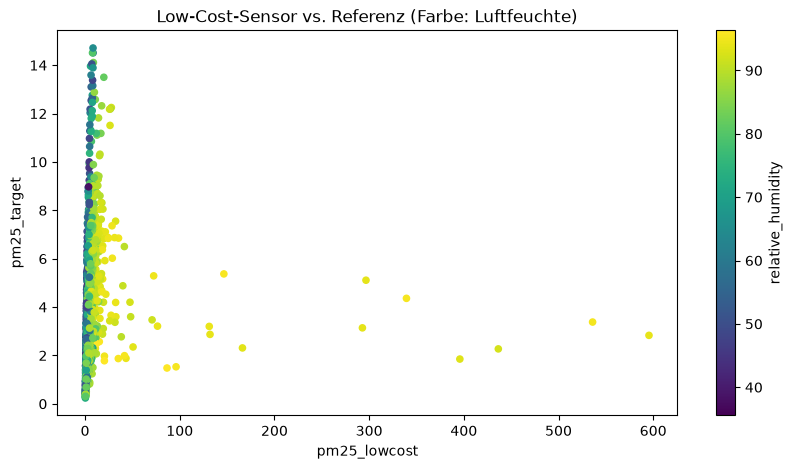

              gekappt Train %  gekappt Test %
pm25_lowcost              7.0            23.5
no                       11.5            19.3
no2                       2.5             2.5
black_carbon              6.4             5.5
ufp                       2.1             0.1
co2                       0.8             0.9


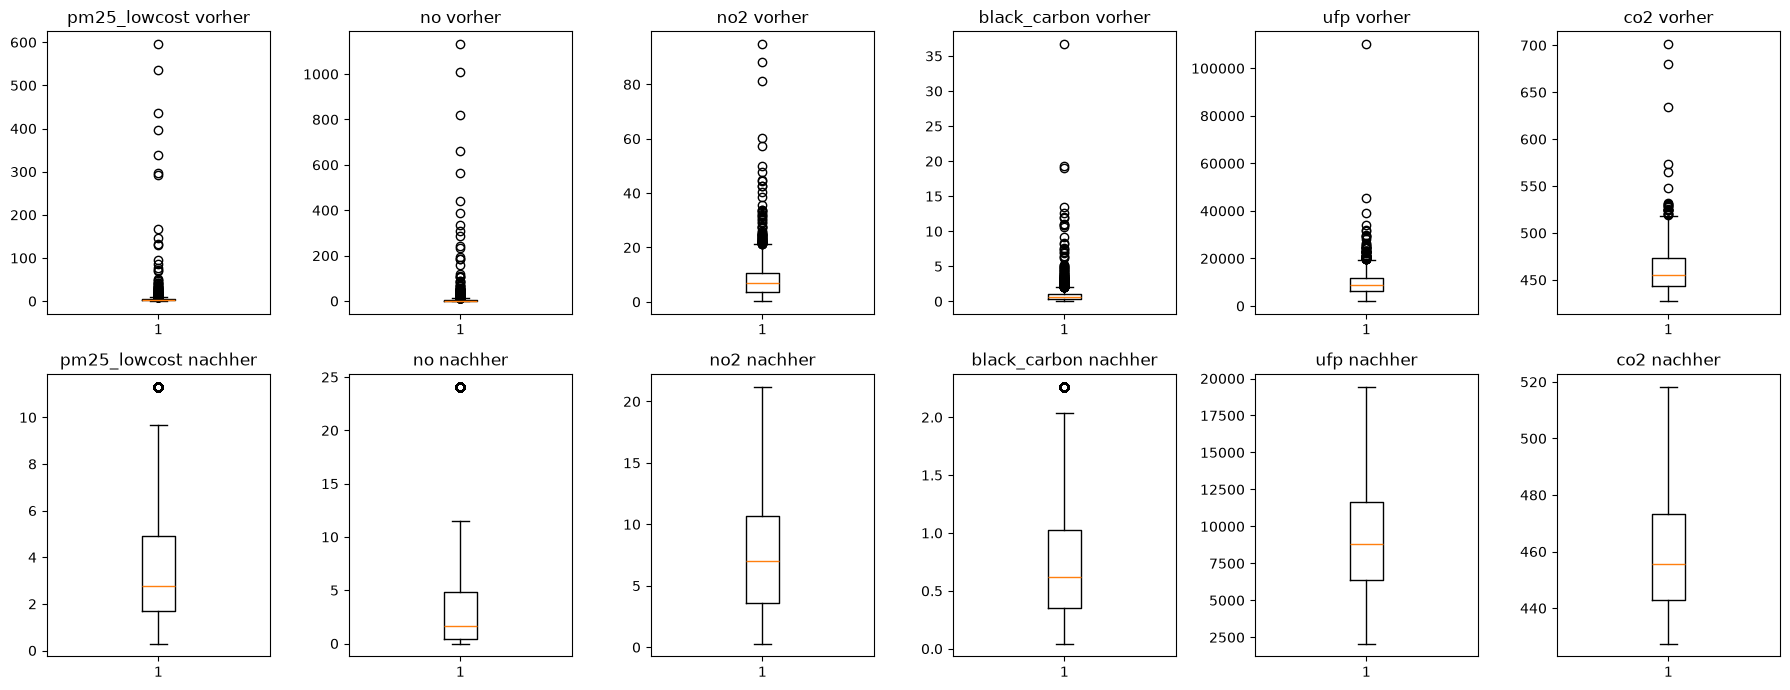

,Modell,Art,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_%,dR2_abs,Übernommen
0,Negativwerte auf 0,kumulativ,1.3257,1.3412,0.3186,0.3594,-0.0005,-0.0382,0.0004,ja
1,Ausreißer gekappt,kumulativ,0.8627,0.8751,0.6865,0.6860,-0.4666,-34.7739,0.3270,ja
2,Ausreißer gekappt,isoliert,0.8637,0.8754,0.6861,0.6856,-0.4663,-34.7523,0.3266,-


In [7]:
OUTLIER_COLS = ["pm25_lowcost", "no", "no2", "black_carbon", "ufp", "co2"]

train_cur.plot.scatter(x="pm25_lowcost", y=LABEL, c="relative_humidity", colormap="viridis",
                       sharex=False, figsize=(10, 5), title="Low-Cost-Sensor vs. Referenz (Farbe: Luftfeuchte)")
plt.show()


def cap_outliers(train_df, val_df, test_df):
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    for col in OUTLIER_COLS:
        # Grenzen nur aus den Trainingsdaten
        q1 = train_df[col].quantile(0.25)
        q3 = train_df[col].quantile(0.75)
        lower = q1 - 1.5 * (q3 - q1)
        upper = q3 + 1.5 * (q3 - q1)
        p5 = train_df[col].quantile(0.05)
        p95 = train_df[col].quantile(0.95)
        for data in [train_df, val_df, test_df]:
            data[col] = np.where(data[col] < lower, p5, data[col])
            data[col] = np.where(data[col] > upper, p95, data[col])
    return train_df, val_df, test_df


tr, va, te = cap_outliers(train_cur, valid_cur, test_cur)
check_integrity(va, te)
r_ausreisser = evaluate("Ausreißer gekappt", "kumulativ", "IQR-Ausreißer der Schadstoffe durch 5./95. Perzentil ersetzt", tr, va)
tr_i, va_i, te_i = cap_outliers(train, valid, test)
r_ausreisser_iso = evaluate("Ausreißer gekappt", "isoliert", "IQR-Ausreißer der Schadstoffe durch 5./95. Perzentil ersetzt", tr_i, va_i)

# Vorher/Nachher: Anteil gekappter Werte und Boxplots (Training)
print(pd.DataFrame({
    "gekappt Train %": ((train_cur[OUTLIER_COLS] != tr[OUTLIER_COLS]) & train_cur[OUTLIER_COLS].notnull()).sum() / len(tr) * 100,
    "gekappt Test %": ((test_cur[OUTLIER_COLS] != te[OUTLIER_COLS]) & test_cur[OUTLIER_COLS].notnull()).sum() / len(te) * 100}).round(1))
fig, axs = plt.subplots(2, len(OUTLIER_COLS), figsize=(18, 7))
for i in range(len(OUTLIER_COLS)):
    col = OUTLIER_COLS[i]
    axs[0, i].boxplot(train_cur[col].dropna())
    axs[0, i].set_title(col + " vorher")
    axs[1, i].boxplot(tr[col].dropna())
    axs[1, i].set_title(col + " nachher")
plt.tight_layout()
plt.show()

if improves(r_ausreisser):
    train_cur, valid_cur, test_cur, current = tr, va, te, r_ausreisser
    path.append(r_ausreisser)
    adopt(r_ausreisser, "ja", "MAE sinkt deutlich")
show([r_negativ, r_ausreisser, r_ausreisser_iso])

- Die extremen Low-Cost-Werte treten fast nur bei hoher Luftfeuchte auf (gelb). Dann nehmen die Partikel Wasser auf und der Sensor misst zu viel, es sind also Messfehler.
- Größter Sprung: Der MAE sinkt von 1,341 auf 0,875 (−35 %), R² steigt von 0,36 auf 0,69.
- Im Test werden 23,5 % der Low-Cost-Werte gekappt, im Training nur 7 % (siehe Abschnitt 6).

### 4.3 Fehlende Werte
Die Lücken unterscheiden sich stark: kurze Ausfälle von wenigen Stunden, Sensorausfälle über Wochen, und die Wetterdaten fehlen immer gemeinsam. Deshalb wird je Feature das Verfahren gewählt, das ausgeblendete Trainingswerte am genauesten schätzt:
- kurze Lücken: Mittelwert der Nachbarstunden (±3 h)
- lange Lücken: Regression aus korrelierten Features, die in den Lücken vorhanden sind, sonst Median

Für die Entscheidung werden im Training 20 % der bekannten Werte ausgeblendet und mit jedem Verfahren geschätzt.

In [8]:
features_now = feature_columns(train_cur)
# Reihenfolge: zuerst Features, deren Prädiktoren fast vollständig sind, pm25_lowcost zuletzt
IMPUTE_PREDICTORS = {
    "no": ["black_carbon"], "no2": ["black_carbon"], "black_carbon": ["no", "no2"], "ufp": ["no", "no2"],
    "co2": ["no", "no2"], "o3": ["relative_humidity", "no2"], "relative_humidity": ["o3", "no2"],
    "temperature": ["o3", "no2"], "pm25_lowcost": ["relative_humidity", "no2", "black_carbon"],
    "pressure": ["o3", "no2"], "wind_speed": ["o3", "no2"], "wind_direction": ["o3", "no2"],
    "rain_vol": ["o3", "no2"], "glob_rad": ["o3", "no2"]}

# chronologische Zeitachse der Trainingsdatei (Stunden ohne Label bleiben leer)
timeline = df[["timestamp"]].join(pd.concat([train_cur, valid_cur])[features_now])

rows = []
for target in IMPUTE_PREDICTORS:
    predictors = IMPUTE_PREDICTORS[target]
    known = train_cur[train_cur[[target] + predictors].isnull().sum(axis=1) == 0]
    fit_part, hidden = train_test_split(known, test_size=0.2, random_state=1)
    reg = linear_model.LinearRegression()
    reg.fit(fit_part[predictors], fit_part[target])
    series = timeline[target].copy()
    series.loc[hidden.index] = np.nan          # ausgeblendete Werte nicht als Nachbarn verwenden
    neighbors = series.rolling(window=7, center=True, min_periods=1).mean().loc[hidden.index]
    mae_median = mean_absolute_error(hidden[target], [fit_part[target].median()] * len(hidden))
    mae_reg = mean_absolute_error(hidden[target], reg.predict(hidden[predictors]))
    r2 = reg.score(hidden[predictors], hidden[target])
    rows.append({"Feature": target,
                 "fehlend Train %": df[target].isnull().mean() * 100, "fehlend Test %": test[target].isnull().mean() * 100,
                 "MAE Nachbarstunden": mean_absolute_error(hidden[target][neighbors.notnull()], neighbors[neighbors.notnull()]),
                 "MAE Median": mae_median, "MAE Regression": mae_reg, "R2 Regression": r2,
                 "lange Lücken": "Regression " + str(predictors) if r2 >= 0.3 and mae_reg < mae_median else "Median"})
decision = pd.DataFrame(rows).set_index("Feature")
REG_FEATURES = list(decision[decision["lange Lücken"] != "Median"].index)
decision.round(2)

,fehlend Train %,fehlend Test %,MAE Nachbarstunden,MAE Median,MAE Regression,R2 Regression,lange Lücken
Feature,,,,,,,
no,0.61,0.14,2.26,4.18,3.31,0.56,Regression ['black_carbon']
no2,0.61,0.14,2.08,4.09,2.61,0.52,Regression ['black_carbon']
black_carbon,0.06,48.70,0.17,0.41,0.20,0.75,"Regression ['no', 'no2']"
ufp,21.51,42.01,1484.70,3204.79,2364.61,0.40,"Regression ['no', 'no2']"
co2,25.66,58.61,4.40,16.13,11.58,0.39,"Regression ['no', 'no2']"
o3,20.68,10.66,3.78,11.61,5.57,0.74,"Regression ['relative_humidity', 'no2']"
relative_humidity,11.85,67.28,3.18,11.82,6.01,0.69,"Regression ['o3', 'no2']"
temperature,11.85,67.28,0.64,4.11,3.03,0.49,"Regression ['o3', 'no2']"
pm25_lowcost,12.76,0.20,0.64,2.00,1.76,0.33,"Regression ['relative_humidity', 'no2', 'black..."


                   Train vorher  Train nachher  Test vorher  Test nachher
pm25_lowcost                263              0            3             0
no                           13              0            2             0
no2                          13              0            2             0
o3                          586              0          156             0
co2                         756              0          858             0
black_carbon                  0              0          713             0
ufp                         458              0          615             0
temperature                 312              0          985             0
relative_humidity           312              0          985             0
pressure                    312              0          985             0
wind_speed                  312              0          985             0
wind_direction              312              0          985             0
rain_vol                    312       

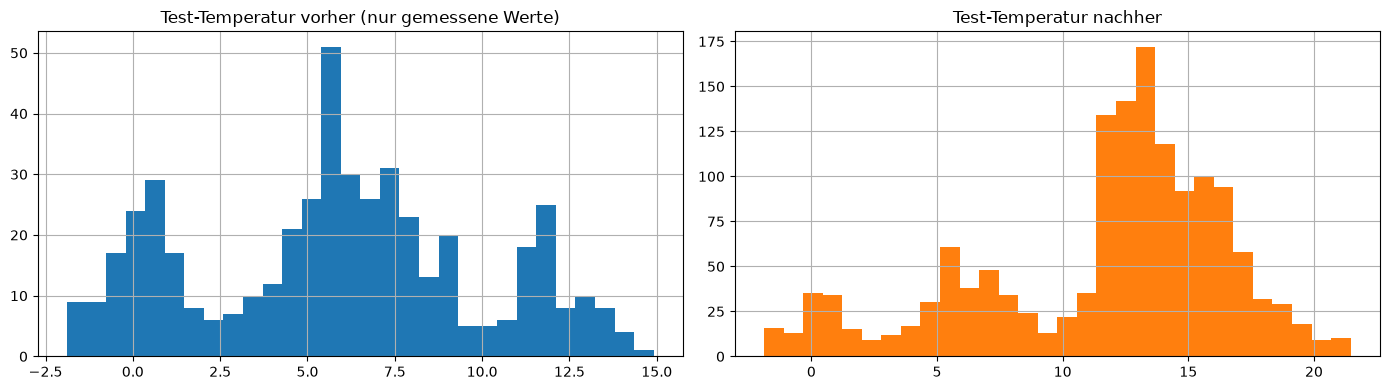

,Modell,Art,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_%,dR2_abs,Übernommen
0,Imputation nur Median,kumulativ,0.8627,0.8751,0.6865,0.6860,-0.4666,-34.7739,0.3270,nein
1,Imputation je Feature,kumulativ,0.8362,0.8409,0.7023,0.7139,-0.5008,-37.3256,0.3549,ja
2,Imputation je Feature,isoliert,1.3087,1.3269,0.3540,0.3998,-0.0148,-1.0998,0.0408,-


In [9]:
def fill_from_neighbors(train_df, val_df, test_df):
    # Mittelwert der Messungen +-3 Stunden, Trainings- und Testdatei jeweils chronologisch
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    features = feature_columns(train_df)
    timeline = df[["timestamp"]].join(pd.concat([train_df, val_df])[features])
    neighbors_train = timeline[features].rolling(window=7, center=True, min_periods=1).mean()
    neighbors_test = test_df[features].rolling(window=7, center=True, min_periods=1).mean()
    train_df[features] = train_df[features].fillna(neighbors_train.loc[train_df.index])
    val_df[features] = val_df[features].fillna(neighbors_train.loc[val_df.index])
    test_df[features] = test_df[features].fillna(neighbors_test)
    return train_df, val_df, test_df


def regression_impute(train_df, val_df, test_df):
    # Regressionen nur auf den Trainingsdaten lernen
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    for target in REG_FEATURES:
        predictors = IMPUTE_PREDICTORS[target]
        predictor_median = train_df[predictors].median()
        known = train_df[target].notnull()
        reg = linear_model.LinearRegression()
        reg.fit(train_df.loc[known, predictors].fillna(predictor_median), train_df.loc[known, target])
        for data in [train_df, val_df, test_df]:
            missing = data[target].isnull()
            if missing.sum() > 0:
                data.loc[missing, target] = reg.predict(data.loc[missing, predictors].fillna(predictor_median))
    return train_df, val_df, test_df


def impute_median(train_df, val_df, test_df):
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    features = feature_columns(train_df)
    median = train_df[features].median()
    for data in [train_df, val_df, test_df]:
        data[features] = data[features].fillna(median)
    return train_df, val_df, test_df


def impute_per_feature(train_df, val_df, test_df):
    tr, va, te = fill_from_neighbors(train_df, val_df, test_df)
    tr, va, te = regression_impute(tr, va, te)
    return impute_median(tr, va, te)


# Vergleich: nur Median vs. Verfahren je Feature
tr_m, va_m, te_m = impute_median(train_cur, valid_cur, test_cur)
r_mv_median = evaluate("Imputation nur Median", "kumulativ", "alle Lücken mit Trainings-Median", tr_m, va_m)
tr, va, te = impute_per_feature(train_cur, valid_cur, test_cur)
check_integrity(va, te)
r_mv = evaluate("Imputation je Feature", "kumulativ", "Nachbarstunden, Regression für " + str(REG_FEATURES) + ", Rest Median", tr, va)
tr_i, va_i, te_i = impute_per_feature(train, valid, test)
r_mv_iso = evaluate("Imputation je Feature", "isoliert", "Nachbarstunden, Regression, Rest Median", tr_i, va_i)

# Vorher/Nachher: fehlende Werte und Test-Temperatur
print(pd.DataFrame({"Train vorher": train_cur[features_now].isnull().sum(), "Train nachher": tr[features_now].isnull().sum(),
                    "Test vorher": test_cur[features_now].isnull().sum(), "Test nachher": te[features_now].isnull().sum()}))
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
test_cur["temperature"].hist(bins=30, ax=axs[0])
axs[0].set_title("Test-Temperatur vorher (nur gemessene Werte)")
te["temperature"].hist(bins=30, ax=axs[1], color="tab:orange")
axs[1].set_title("Test-Temperatur nachher")
plt.tight_layout()
plt.show()

if improves(r_mv):
    train_cur, valid_cur, test_cur, current = tr, va, te, r_mv
    adopt(r_mv, "ja", "genauer als nur Median")
    adopt(r_mv_median, "nein", "schlechter als Imputation je Feature")
else:
    train_cur, valid_cur, test_cur, current = tr_m, va_m, te_m, r_mv_median
    adopt(r_mv_median, "ja", "Imputation je Feature bringt keine Verbesserung")
    adopt(r_mv, "nein", "nicht besser als Median")
path.append(current)
show([r_mv_median, r_mv, r_mv_iso])

- Kurze Lücken: Die Nachbarstunden sind am genauesten (Temperatur 0,64 °C statt 4,1 °C mit dem Median).
- Lange Lücken: Die Regression ist für 9 Features deutlich genauer als der Median (z. B. `o3` 5,6 statt 11,6). Für Druck, Wind, Regen und Strahlung gibt es keinen brauchbaren Zusammenhang (R² < 0,25), dort bleibt der Median.
- Im Modell sinkt der MAE von 0,875 (nur Median) auf 0,841.
- Einschränkung: `black_carbon` fehlt nur im Test in größerem Umfang (49 %), die Validierung kann diesen Fall nicht prüfen. Die imputierten Wintertemperaturen sind noch zu hoch, weil der Zusammenhang mit `o3` im Sommer gelernt wurde.

### 4.4 Feature Engineering
Neues Feature `lowcost_x_humidity = pm25_lowcost * relative_humidity`. Wie gut der Low-Cost-Wert ist, hängt von der Luftfeuchte ab (siehe 4.2). Das kann die lineare Regression ohne dieses Feature nicht abbilden.

In [10]:
def add_interaction(train_df, val_df, test_df):
    result = []
    for data in [train_df, val_df, test_df]:
        data = data.copy()
        data["lowcost_x_humidity"] = data["pm25_lowcost"] * data["relative_humidity"]
        result.append(data)
    return result[0], result[1], result[2]


tr, va, te = add_interaction(train_cur, valid_cur, test_cur)
check_integrity(va, te)
print(tr[["pm25_lowcost", "relative_humidity", "lowcost_x_humidity"]].head(3))
r_interaktion = evaluate("Interaktion Lowcost x Feuchte", "kumulativ", "neues Feature lowcost_x_humidity", tr, va)
tr_i, va_i, te_i = add_interaction(train, valid, test)
r_interaktion_iso = evaluate("Interaktion Lowcost x Feuchte", "isoliert", "neues Feature lowcost_x_humidity", tr_i, va_i)
if improves(r_interaktion):
    train_cur, valid_cur, test_cur, current = tr, va, te, r_interaktion
    path.append(r_interaktion)
    adopt(r_interaktion, "ja", "MAE sinkt deutlich")
show([r_mv, r_interaktion, r_interaktion_iso])

      pm25_lowcost  relative_humidity  lowcost_x_humidity
2455          2.21             81.167           179.37907
2370          6.42             81.791           525.09822
1779          1.25             43.815            54.76875


,Modell,Art,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_%,dR2_abs,Übernommen
0,Imputation je Feature,kumulativ,0.8362,0.8409,0.7023,0.7139,-0.5008,-37.3256,0.3549,ja
1,Interaktion Lowcost x Feuchte,kumulativ,0.7586,0.7621,0.7614,0.7872,-0.5796,-43.1983,0.4281,ja
2,Interaktion Lowcost x Feuchte,isoliert,1.1399,1.1605,0.4642,0.5058,-0.1812,-13.5055,0.1468,-


Zweitgrößter Sprung: Der MAE sinkt von 0,841 auf 0,762, R² steigt von 0,714 auf 0,787.

### 4.5 Transformation und Skalierung
Geprüft werden ein PowerTransformer (Yeo-Johnson) für Features mit |Schiefe| > 1 und ein StandardScaler für alle Features.

In [11]:
skew = train_cur[feature_columns(train_cur)].skew()
SKEW_COLS = list(skew[skew.abs() > 1].index)


def power_transform(train_df, val_df, test_df, columns):
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    transformer = PowerTransformer()
    transformer.fit(train_df[columns])
    for data in [train_df, val_df, test_df]:
        data[columns] = transformer.transform(data[columns])
    return train_df, val_df, test_df


def standard_scale(train_df, val_df, test_df):
    train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()
    features = feature_columns(train_df)
    scaler = StandardScaler()
    scaler.fit(train_df[features])
    for data in [train_df, val_df, test_df]:
        data[features] = scaler.transform(data[features])
    return train_df, val_df, test_df


tr, va, te = power_transform(train_cur, valid_cur, test_cur, SKEW_COLS)
r_power = evaluate("PowerTransformer", "kumulativ", "PowerTransformer auf " + str(SKEW_COLS), tr, va)
iso_cols = [col for col in SKEW_COLS if col in train.columns]
tr_i, va_i, te_i = power_transform(train, valid, test, iso_cols)
r_power_iso = evaluate("PowerTransformer", "isoliert", "PowerTransformer auf " + str(iso_cols), tr_i, va_i)
print("Schiefe vorher / nachher PowerTransformer:")
print(pd.DataFrame({"vorher": skew[SKEW_COLS], "nachher": tr[SKEW_COLS].skew()}).round(2))
if improves(r_power):
    train_cur, valid_cur, test_cur, current = tr, va, te, r_power
    path.append(r_power)
    adopt(r_power, "ja", "MAE sinkt")
else:
    adopt(r_power, "nein", "MAE steigt")

tr_s, va_s, te_s = standard_scale(train_cur, valid_cur, test_cur)
r_scaler = evaluate("StandardScaler", "kumulativ", "StandardScaler auf allen Features", tr_s, va_s)
tr_i, va_i, te_i = standard_scale(train, valid, test)
r_scaler_iso = evaluate("StandardScaler", "isoliert", "StandardScaler auf allen Features", tr_i, va_i)

# Warum ändert die Skalierung nichts? Koeffizienten vorher und nachher
features = feature_columns(train_cur)
reg_raw = linear_model.LinearRegression()
reg_raw.fit(train_cur[features], train_cur[LABEL])
reg_std = linear_model.LinearRegression()
reg_std.fit(tr_s[features], tr_s[LABEL])
std = train_cur[features].std(ddof=0).values      # wie im StandardScaler
print(pd.DataFrame({"Koef. unskaliert": reg_raw.coef_, "Std.-Abw.": std,
                    "unskaliert * Std.-Abw.": reg_raw.coef_ * std, "Koef. standardisiert": reg_std.coef_},
                   index=features).round(4))

train_cur, valid_cur, test_cur, current = tr_s, va_s, te_s, r_scaler
path.append(r_scaler)
adopt(r_scaler, "ja", "MAE unverändert, Koeffizienten vergleichbar, wichtig für Aufgabe 3")
check_integrity(valid_cur, test_cur)
show([r_interaktion, r_power, r_power_iso, r_scaler, r_scaler_iso])

Schiefe vorher / nachher PowerTransformer:
                    vorher  nachher
pm25_lowcost          1.42    -0.00
no                    1.95     0.10
black_carbon          1.18     0.09
wind_speed            1.45     0.04
glob_rad              1.75    -0.00
lowcost_x_humidity    1.59     0.39
                    Koef. unskaliert  Std.-Abw.  unskaliert * Std.-Abw.  \
pm25_lowcost                  2.2342     2.8338                  6.3314   
no                           -0.0401     7.4221                 -0.2973   
no2                          -0.0349     4.8955                 -0.1708   
o3                            0.0266    13.1269                  0.3498   
co2                           0.0206    18.3262                  0.3772   
black_carbon                  1.6527     0.5761                  0.9520   
ufp                          -0.0000  3652.4770                 -0.1105   
temperature                   0.1306     4.8474                  0.6330   
relative_humidity             

,Modell,Art,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_%,dR2_abs,Übernommen
0,Interaktion Lowcost x Feuchte,kumulativ,0.7586,0.7621,0.7614,0.7872,-0.5796,-43.1983,0.4281,ja
1,PowerTransformer,kumulativ,0.8256,0.8319,0.7087,0.7240,-0.5098,-37.9968,0.3650,nein
2,PowerTransformer,isoliert,0.8689,0.8966,0.6771,0.6692,-0.4451,-33.1730,0.3102,-
3,StandardScaler,kumulativ,0.7586,0.7621,0.7614,0.7872,-0.5796,-43.1983,0.4281,ja
4,StandardScaler,isoliert,1.3261,1.3417,0.3183,0.3590,0.0000,0.0000,0.0000,-


- Der PowerTransformer macht die Verteilungen symmetrisch, verschlechtert das Modell aber (MAE 0,832 statt 0,762) und wird nicht übernommen.
- Der StandardScaler ändert nichts, weil die lineare Regression die Skalierung über die Koeffizienten ausgleicht (standardisierter Koeffizient = unskalierter × Standardabweichung). Übernommen wird er trotzdem, weil KNN in Aufgabe 3 skalierte Daten braucht.
- Die wichtigsten Features sind `pm25_lowcost` (+6,3) und die Interaktion (−5,2): Je höher die Luftfeuchte, desto stärker wird der Low-Cost-Wert nach unten korrigiert.

### 4.6 Feature Selection
Kandidaten zum Entfernen: Features mit |r| < 0,05 zum Label, das Feature mit dem höchsten VIF und `no2` (aus 1b).

In [12]:
def calc_vif(df):
    vif = pd.DataFrame()
    vif["features"] = df.columns
    vif["VIF Factor"] = [variance_inflation_factor(df.values, i) for i in range(df.shape[1])]
    return vif


features = feature_columns(train_cur)
corr_with_label = train_cur[features].corrwith(train_cur[LABEL])
vif_table = calc_vif(train_cur[features]).set_index("features")
print(pd.DataFrame({"r mit Label": corr_with_label, "VIF": vif_table["VIF Factor"]}).round(2).sort_values("VIF", ascending=False))

candidates = list(corr_with_label[corr_with_label.abs() < 0.05].index) + [vif_table["VIF Factor"].sort_values().index[-1], "no2"]
rows = []
for col in candidates:
    tr, va, te = train_cur.drop(columns=[col]), valid_cur.drop(columns=[col]), test_cur.drop(columns=[col])
    row = evaluate("ohne " + col, "kumulativ", col + " entfernt", tr, va)
    rows.append(row)
    if improves(row):
        train_cur, valid_cur, test_cur, current = tr, va, te, row
        path.append(row)
        adopt(row, "ja", "MAE sinkt")
    else:
        adopt(row, "nein", "MAE steigt oder R² sinkt")
check_integrity(valid_cur, test_cur)
show([current] + rows)

                    r mit Label    VIF
lowcost_x_humidity         0.54  94.14
pm25_lowcost               0.61  83.26
o3                        -0.06   7.10
relative_humidity          0.13   6.46
black_carbon               0.50   5.11
no2                        0.29   4.82
temperature                0.10   3.28
co2                        0.28   3.16
no                         0.23   2.90
ufp                        0.24   2.15
rain_vol                   0.00   1.88
glob_rad                   0.06   1.77
pressure                   0.24   1.42
wind_speed                -0.16   1.41
wind_direction            -0.18   1.21


,Modell,Art,MAE_Train,MAE_Val,R2_Train,R2_Val,dMAE_abs,dMAE_%,dR2_abs,Übernommen
0,StandardScaler,kumulativ,0.7586,0.7621,0.7614,0.7872,-0.5796,-43.1983,0.4281,ja
1,ohne rain_vol,kumulativ,0.7580,0.7614,0.7607,0.7863,-0.5803,-43.2515,0.4273,nein
2,ohne lowcost_x_humidity,kumulativ,0.8362,0.8409,0.7023,0.7139,-0.5008,-37.3256,0.3549,nein
3,ohne no2,kumulativ,0.7619,0.7692,0.7601,0.7840,-0.5725,-42.6705,0.4249,nein


- Kein Feature wird entfernt. Ohne `rain_vol` sinkt der MAE zwar minimal, R² wird aber schlechter.
- Der hohe VIF der Interaktion ist strukturell bedingt, weil sie aus `pm25_lowcost` berechnet wird. Da es um die Vorhersage geht, bleibt sie im Modell.

## 5. Übersicht aller Modelle

Finale Kombination: Negativwerte auf 0 + Ausreißer gekappt + Imputation je Feature + Interaktion Lowcost x Feuchte + StandardScaler
                               MAE_Train  MAE_Val  R2_Val  dMAE_abs   dMAE_%  \
Modell                                                                         
Baseline                          1.3261   1.3417  0.3590    0.0000   0.0000   
Negativwerte auf 0                1.3257   1.3412  0.3594   -0.0005  -0.0382   
Ausreißer gekappt                 0.8627   0.8751  0.6860   -0.4666 -34.7739   
Imputation je Feature             0.8362   0.8409  0.7139   -0.5008 -37.3256   
Interaktion Lowcost x Feuchte     0.7586   0.7621  0.7872   -0.5796 -43.1983   
StandardScaler                    0.7586   0.7621  0.7872   -0.5796 -43.1983   

                               dR2_abs  
Modell                                  
Baseline                        0.0000  
Negativwerte auf 0              0.0004  
Ausreißer gekappt               0.3270  
Imputation je Feature 

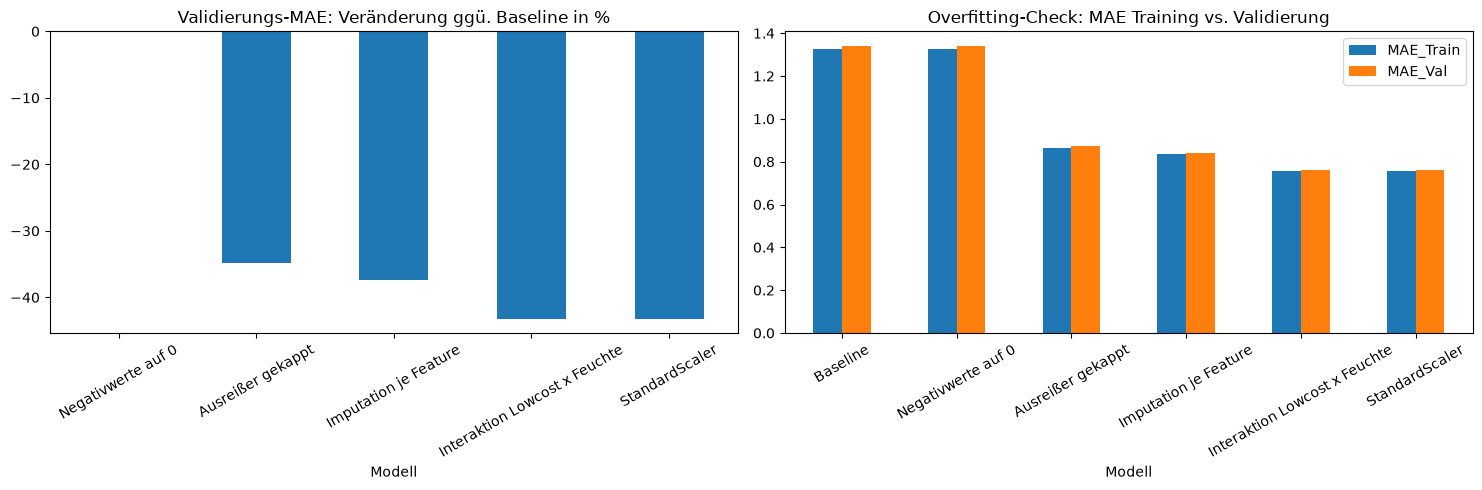

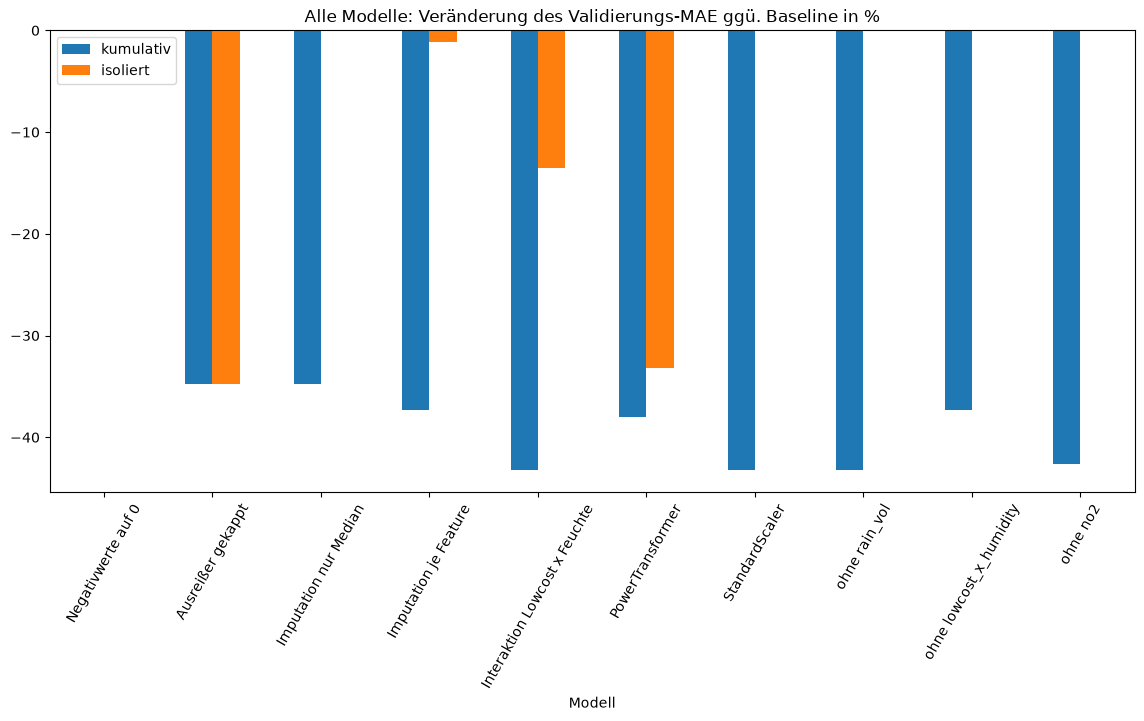

In [13]:
combination = ""
for row in path[1:]:
    combination = row["Modell"] if combination == "" else combination + " + " + row["Modell"]
print("Finale Kombination:", combination)

path_df = show(path).set_index("Modell")
print(path_df[["MAE_Train", "MAE_Val", "R2_Val", "dMAE_abs", "dMAE_%", "dR2_abs"]])

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
path_df["dMAE_%"].iloc[1:].plot.bar(ax=axs[0], rot=30, title="Validierungs-MAE: Veränderung ggü. Baseline in %")
path_df[["MAE_Train", "MAE_Val"]].plot.bar(ax=axs[1], rot=30, title="Overfitting-Check: MAE Training vs. Validierung")
plt.tight_layout()
plt.show()

all_results = pd.DataFrame(results)
comparison = pd.DataFrame({"kumulativ": all_results[all_results["Art"] == "kumulativ"].set_index("Modell")["dMAE_%"]})
comparison["isoliert"] = all_results[all_results["Art"] == "isoliert"].set_index("Modell")["dMAE_%"]
comparison.plot.bar(figsize=(14, 6), rot=60, title="Alle Modelle: Veränderung des Validierungs-MAE ggü. Baseline in %")
plt.show()

- Insgesamt sinkt der Validierungs-MAE um 43,2 % (von 1,342 auf 0,762), vor allem durch das Kappen und die Interaktion.
- Training und Validierung liegen nah beieinander (Abstand höchstens 0,016), es gibt also kein Overfitting.
- Isoliert und kombiniert wirken Schritte teils unterschiedlich, z. B. der PowerTransformer.

## 6. Finaler Test
Baseline und finales Modell werden einmalig auf den Testdaten bewertet. Alle 1.464 Testzeilen bekommen eine Vorhersage, MAE und R² werden auf den 1.419 Zeilen mit Label berechnet.

                MAE_Val  MAE_Test  R2_Val  R2_Test  MAE_Test_%
Baseline         1.3417    2.2193  0.3590  -0.1453      0.0000
Finales Modell   0.7621    1.6764  0.7872   0.3792    -24.4616


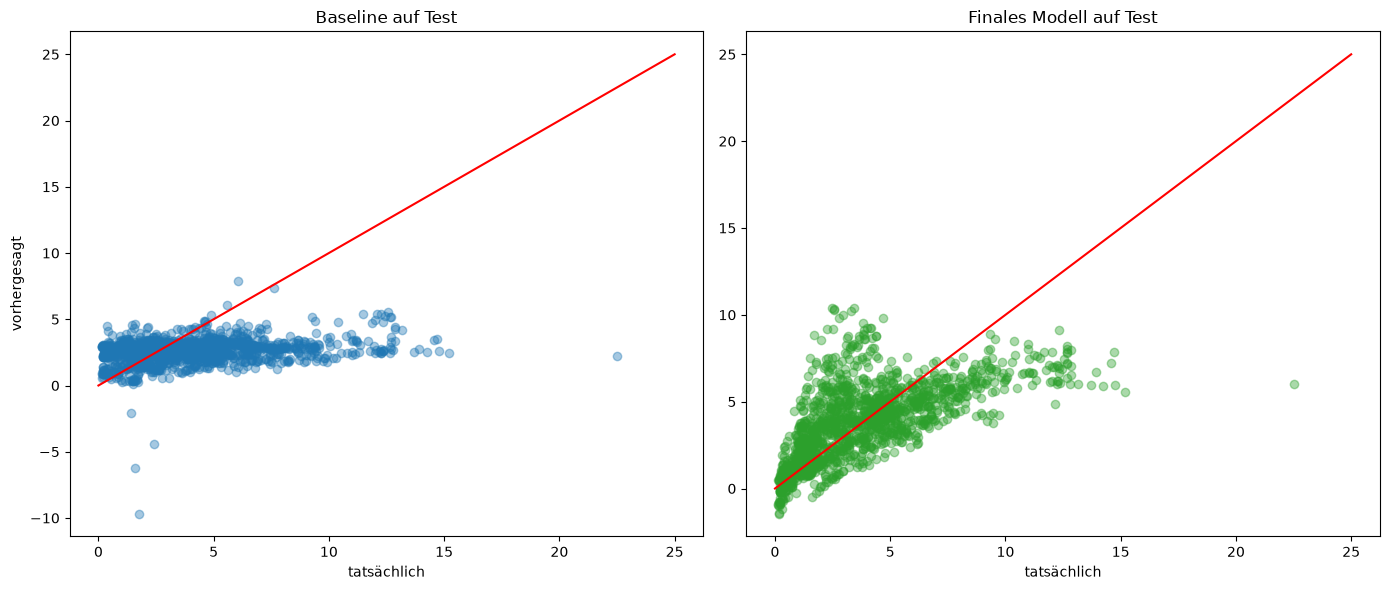


MAE nach Monat:
year_month
2024-11    1.447
2024-12    1.885
Name: pm25_target, dtype: float64

MAE nach pm25_lowcost gekappt (True) / nicht gekappt (False):
pm25_lowcost
False    1.322
True     2.835
Name: pm25_target, dtype: float64


In [14]:
def evaluate_test(name, train_df, test_df):
    features = feature_columns(train_df)
    median = train_df[features].median()          # nur für die Baseline relevant
    X_train = train_df[features].fillna(median)
    X_test = test_df[features].fillna(median)
    reg = linear_model.LinearRegression()
    reg.fit(X_train, train_df[LABEL])
    prediction = reg.predict(X_test)
    has_label = test_df[LABEL].notnull()
    mae = mean_absolute_error(test_df[LABEL][has_label], prediction[has_label.values])
    r2 = reg.score(X_test[has_label], test_df[LABEL][has_label])
    with open(LOG_FILE, "a", encoding="utf-8") as log:
        log.write(f"TEST {name} | {len(test_df)} Zeilen, {has_label.sum()} bewertet | MAE Test {mae:.4f} | R2 Test {r2:.4f}\n")
    return {"MAE_Test": mae, "R2_Test": r2}, prediction


test_baseline, pred_baseline = evaluate_test("Baseline", train, test)
test_final, pred_final = evaluate_test("Finales Modell", train_cur, test_cur)
check_integrity(valid_cur, test_cur)

final_overview = pd.DataFrame({
    "MAE_Val": [baseline["MAE_Val"], current["MAE_Val"]],
    "MAE_Test": [test_baseline["MAE_Test"], test_final["MAE_Test"]],
    "R2_Val": [baseline["R2_Val"], current["R2_Val"]],
    "R2_Test": [test_baseline["R2_Test"], test_final["R2_Test"]]}, index=["Baseline", "Finales Modell"])
final_overview["MAE_Test_%"] = (final_overview["MAE_Test"] / test_baseline["MAE_Test"] - 1) * 100
print(final_overview.round(4))

has_label = test[LABEL].notnull()
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
axs[0].scatter(test.loc[has_label, LABEL], pred_baseline[has_label.values], alpha=0.4)
axs[0].plot([0, 25], [0, 25], color="red")
axs[0].set_title("Baseline auf Test")
axs[0].set_xlabel("tatsächlich")
axs[0].set_ylabel("vorhergesagt")
axs[1].scatter(test.loc[has_label, LABEL], pred_final[has_label.values], alpha=0.4, color="tab:green")
axs[1].plot([0, 25], [0, 25], color="red")
axs[1].set_title("Finales Modell auf Test")
axs[1].set_xlabel("tatsächlich")
plt.tight_layout()
plt.show()

# Warum ist der Test schlechter als die Validierung?
abs_error = (test[LABEL] - pred_final).abs()
q1, q3 = train["pm25_lowcost"].quantile(0.25), train["pm25_lowcost"].quantile(0.75)
fence = q3 + 1.5 * (q3 - q1)
print("\nMAE nach Monat:")
print(abs_error.groupby(test["year_month"]).mean().round(3))
print("\nMAE nach pm25_lowcost gekappt (True) / nicht gekappt (False):")
print(abs_error.groupby(test["pm25_lowcost"] > fence).mean().round(3))

- Der Test-MAE sinkt von 2,219 auf 1,676 (−24,5 %), R² steigt von −0,15 auf 0,38. Die relative R²-Veränderung entfällt, weil das R² der Baseline negativ ist.
- Der Test-MAE ist deutlich höher als auf der Validierung (1,68 vs. 0,76). Die Testdaten stammen aus dem Winter, viele Werte liegen außerhalb des Trainingsbereichs: Zeilen mit gekapptem Low-Cost-Wert (23,5 %) haben einen MAE von 2,84, die übrigen 1,32.
- Der Dezember ist schwieriger als der November (1,89 vs. 1,45).

## 7. Export

In [15]:
final_features = feature_columns(train_cur)
export_cols = ["timestamp"] + final_features + [LABEL]
train_cur[export_cols].to_csv(DATA_DIR + "pm25_train_prepared.csv", index=False)
valid_cur[export_cols].to_csv(DATA_DIR + "pm25_validation_prepared.csv", index=False)
test_cur[export_cols].to_csv(DATA_DIR + "pm25_test_prepared.csv", index=False)
pd.DataFrame(results).round(4).to_csv(DATA_DIR + "task2_evaluation.csv", index=False)

check_integrity(valid_cur, test_cur)
print("Training:", train_cur[export_cols].shape, "| Validierung:", valid_cur[export_cols].shape, "| Test:", test_cur[export_cols].shape)

Training: (2727, 17) | Validierung: (682, 17) | Test: (1464, 17)


## 8. Interpretation und Learnings

| | Baseline | Final |
|---|---|---|
| MAE Validierung | 1,342 | 0,762 (−43,2 %) |
| R² Validierung | 0,359 | 0,787 |
| MAE Test | 2,219 | 1,676 (−24,5 %) |
| R² Test | −0,145 | 0,379 |

1. Die Ausreißer haben den Zusammenhang zwischen Low-Cost-Sensor und Referenz verdeckt. Das Kappen war der wichtigste Schritt.
2. Fehlende Werte brauchen je nach Lücke ein anderes Verfahren. Welches passt, zeigt ein Test mit ausgeblendeten Werten.
3. Das Feuchte-Feature kam aus einer Beobachtung in den Daten und brachte den zweitgrößten Sprung.
4. Nicht jeder Schritt hilft: Der PowerTransformer war nach dem Kappen schädlich, die Skalierung ändert bei der linearen Regression nichts.
5. Der Test stammt aus dem Winter. Eine gute Validierung heißt deshalb nicht automatisch ein guter Test.
6. Coding: Parameter nur aus dem Training berechnen, Testzeilen ohne Label nicht löschen, sondern über eine Maske ausblenden, und mit `assert` prüfen, dass Validierung und Test unverändert bleiben.

Ausblick auf Aufgabe 3: nichtlineare Modelle testen und die Kappungsgrenzen für den Winter prüfen. Ein Tageszeit-Feature aus `timestamp` wäre denkbar, wurde hier aber nicht umgesetzt.